# KYC: Bayes, evidencia duplicada y calibración

## Resumen de la ejecución

Datos sintéticos; resultados de esta ejecución:

- **Posterior correcto:** 0.2081
- **Posterior inválido por duplicación:** 0.7293
- **Positivos de prueba:** 26

Los supuestos, límites y contraejemplos se explican junto a cada experimento.

## Objetivo y método

¿Cuánto cambia una probabilidad de fraude con una señal y qué error aparece al contar la misma evidencia dos veces? Derivamos Bayes, construimos un contraejemplo exacto y comparamos logit con calibración posterior.

### Supuestos y población

Una señal binaria tiene sensibilidad y falso positivo conocidos por el simulador. Los bloques de entrenamiento, calibración y prueba se ordenan por índice; su mecanismo es estacionario y las etiquetas están completas.

Todos los datos son sintéticos. Las cifras ilustran mecanismos y no constituyen desempeño observado en una entidad. Fecha de desarrollo: 21 de octubre de 2026.

## Entorno reproducible

Ejecutar en orden, desde esta carpeta o una subcarpeta de la línea de fraude. La semilla y los parámetros quedan en las celdas; no se consulta internet ni se leen datos de clientes.

In [1]:
%matplotlib inline
from pathlib import Path
import sys, math, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.metrics import average_precision_score, brier_score_loss
base = next(p for p in [Path.cwd(), *Path.cwd().parents] if p.name == 'fraud-and-anomaly-research')
sys.path.insert(0, str(base / 'loss-minimization-engine'))
from src.engine import Case, Action, Scenario, optimize, expected_cost, shared_entity_count
rng = np.random.default_rng(20261021)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.figsize': (8, 4.5), 'figure.dpi': 120, 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False, 'grid.alpha': .25})
BLUE, TEAL, GOLD, PURPLE = '#386A96', '#217A72', '#B37D2E', '#73579D'
pd.options.display.float_format = '{:,.4f}'.format

No event loop hook running.


## 1. De prevalencia a probabilidad posterior


Sea $Y=1$ fraude y $E=1$ evidencia positiva. Con prevalencia $\pi$, sensibilidad $s$ y falso positivo $f$:

$$P(Y=1\mid E=1)=\frac{\pi s}{\pi s+(1-\pi)f}.$$

En odds, $O(Y\mid E)=O(Y)LR(E)$ y $LR(E=1)=s/f$. Una señal informativa puede tener precisión baja si la prevalencia es pequeña. No reemplazar $P(Y\mid E)$ por $P(E\mid Y)$.

,prevalencia,sensibilidad,falso_positivo,posterior_positivo
0,0.0250,0.8200,0.0800,0.2081


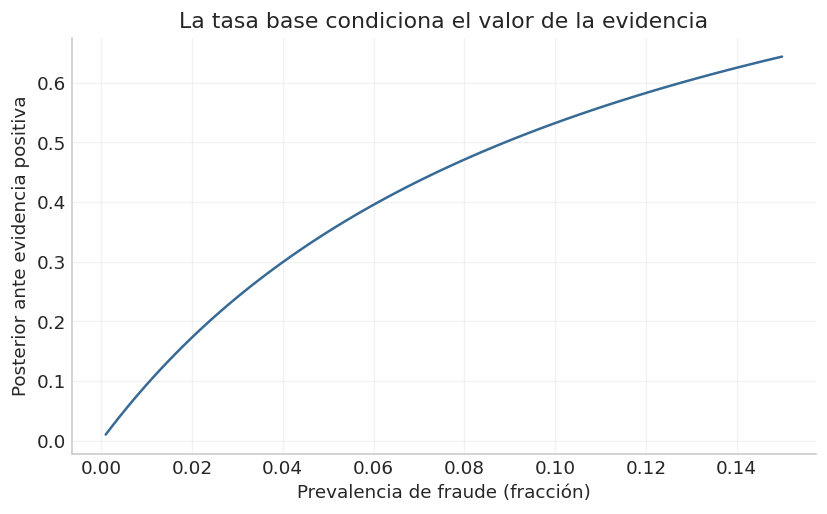

In [2]:
prevalence, sensitivity, false_positive = .025, .82, .08
posterior = prevalence*sensitivity/(prevalence*sensitivity+(1-prevalence)*false_positive)
prior_grid = np.linspace(.001,.15,100)
posterior_grid = prior_grid*sensitivity/(prior_grid*sensitivity+(1-prior_grid)*false_positive)
display(pd.DataFrame({'prevalencia':[prevalence], 'sensibilidad':[sensitivity], 'falso_positivo':[false_positive], 'posterior_positivo':[posterior]}))
fig,ax=plt.subplots();ax.plot(prior_grid,posterior_grid,color=BLUE)
ax.set(xlabel='Prevalencia de fraude (fracción)',ylabel='Posterior ante evidencia positiva',title='La tasa base condiciona el valor de la evidencia')
plt.show()

La curva mantiene fija la calidad de la señal. Cambiar la prevalencia no convierte una misma verificación en una prueba concluyente. Las probabilidades provienen del supuesto conocido, no de una fuente KYC real.

## 2. Contraejemplo: dos campos, una sola evidencia


Si $E_2=E_1$, la información conjunta es la misma. La identidad correcta es
$P(Y\mid E_1,E_2)=P(Y\mid E_1)$. Bajo una independencia falsa se multiplicaría $LR^2$ y se exageraría la confianza.

,método,probabilidad
0,Una evidencia / duplicación correcta,0.2081
1,Duplicación con independencia falsa,0.7293


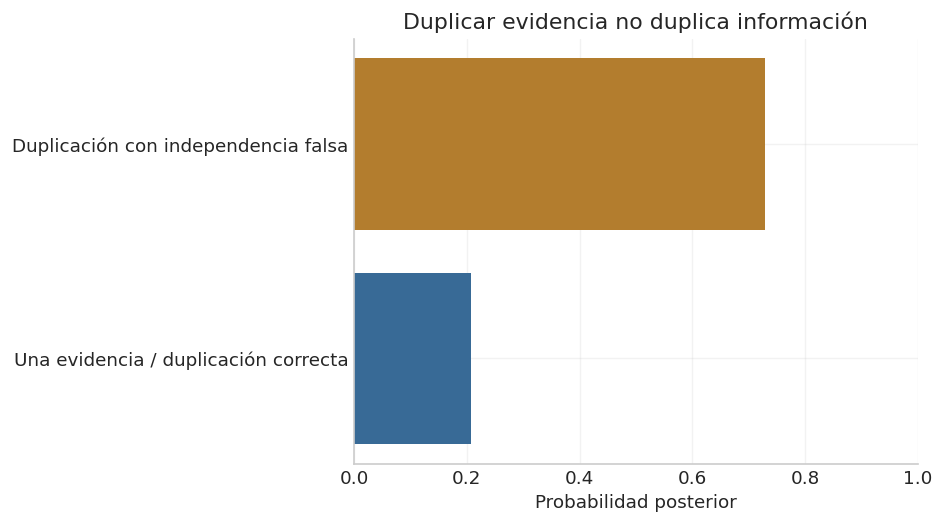

In [3]:
prior_odds=prevalence/(1-prevalence)
likelihood_ratio=sensitivity/false_positive
naive_odds=prior_odds*likelihood_ratio**2
naive_probability=naive_odds/(1+naive_odds)
comparison=pd.DataFrame({'método':['Una evidencia / duplicación correcta','Duplicación con independencia falsa'],
                         'probabilidad':[posterior,naive_probability]})
display(comparison)
fig,ax=plt.subplots();ax.barh(comparison['método'],comparison['probabilidad'],color=[BLUE,GOLD])
ax.set(xlim=(0,1),xlabel='Probabilidad posterior',title='Duplicar evidencia no duplica información');fig.tight_layout();plt.show()

El segundo cálculo es deliberadamente inválido. Dos proveedores que copian el mismo origen no generan automáticamente dos confirmaciones independientes. La trazabilidad de origen importa tanto como el número de campos.

## 3. Estimación y calibración en ventanas separadas


Un logit estima $\hat p=\sigma(\beta_0+\beta^Tx)$ mediante log loss. Un calibrador posterior estima $\tilde p=\sigma(a+b\,\mathrm{logit}(\hat p))$. Las muestras para ambos ajustes son distintas. Brier es $n^{-1}\sum_i(\hat p_i-y_i)^2$.

In [4]:
from sklearn.linear_model import LogisticRegression
n=4000
y=rng.binomial(1,prevalence,n)
e1=rng.binomial(1,np.where(y==1,sensitivity,false_positive))
e2=e1.copy()
x=np.column_stack([e1,e2,rng.normal(size=n)])
train,cal,test=np.arange(2000),np.arange(2000,3000),np.arange(3000,4000)
model=LogisticRegression(C=1,max_iter=500).fit(x[train],y[train])
weighted=LogisticRegression(C=1,class_weight='balanced',max_iter=500).fit(x[train],y[train])
calibrator=LogisticRegression(C=100,max_iter=500).fit(weighted.decision_function(x[cal]).reshape(-1,1),y[cal])
predictions={'logit':model.predict_proba(x[test])[:,1],
             'logit balanceado sin calibrar':weighted.predict_proba(x[test])[:,1],
             'balanceado y calibrado':calibrator.predict_proba(weighted.decision_function(x[test]).reshape(-1,1))[:,1]}
score_table=pd.DataFrame([{'modelo':k,'AP':average_precision_score(y[test],v),'Brier':brier_score_loss(y[test],v),'media_p':v.mean()} for k,v in predictions.items()])
display(score_table)
print('Prevalencia de prueba:',y[test].mean(),'positivos:',y[test].sum())

Prevalencia de prueba: 0.026 positivos: 26


,modelo,AP,Brier,media_p
0,logit,0.2000,0.0221,0.0314
1,logit balanceado sin calibrar,0.2000,0.0974,0.2492
2,balanceado y calibrado,0.2000,0.0224,0.0170


Balancear clases cambia el ajuste y puede alterar la escala probabilística. La tabla permite comprobarlo sin asumir que calibrar siempre mejora. Con pocos positivos, otra semilla o ventana puede modificar el resultado; este notebook no elige hiperparámetros por el test.

## Comprobaciones y límites

Las identidades y contraejemplos siguientes son parte del experimento; no verifican desempeño productivo.

In [5]:
assert posterior < naive_probability < 1
assert np.array_equal(e1,e2)
assert all(np.isfinite(v).all() and ((v>=0)&(v<=1)).all() for v in predictions.values())

## Resultados computados

In [6]:
metrics = {'Posterior correcto': round(posterior,4), 'Posterior inválido por duplicación': round(naive_probability,4), 'Positivos de prueba': int(y[test].sum())}
print("LAB_METRICS:" + json.dumps(metrics, ensure_ascii=False))

LAB_METRICS:{"Posterior correcto": 0.2081, "Posterior inválido por duplicación": 0.7293, "Positivos de prueba": 26}


## Ideas y preguntas para continuar

1. Estimar dependencia entre fuentes y conservar el origen de cada campo.
2. Comparar calibración por proveedor con contracción jerárquica cuando haya pocos positivos.
3. Evaluar degradación al cambiar prevalencia sin cambiar sensibilidad.
4. Investigar reglas de abstención cuando faltan fuentes; faltante no significa legítimo.

## Fuentes y relación con el proyecto

- [Calibración: documentación oficial scikit-learn](https://scikit-learn.org/stable/modules/calibration.html).
- [NIST: identidad y gestión de evidencia](https://pages.nist.gov/800-63-4/sp800-63a.html).
Las derivaciones de Bayes y el contraejemplo se calculan directamente en estas celdas.

Consultar también `../README.md` y `../../MODEL_AND_LOSS_METHODS.md`.